# KMA/MSM – Přednáška 9b: Kopule jako modely závislosti

**Blanka Šedivá, KMA FAV ZČU Plzeň**

Notebook doprovází přednášku P09b (`P09b_kopule.tex`) a navazuje na P09 (korelace).

## Obsah

1. Motivace – stejné marginály, různá závislost
2. Základní kopule $\Pi$, $M$, $W$ a Fréchetovy–Hoeffdingovy meze
3. Sklarova věta v praxi – pseudo-pozorování
4. Parametrické rodiny: Gaussova, $t$, Clayton, Gumbel, Frank
5. Kopule a pořadové míry závislosti – kalibrace parametru z $\hat\tau$
6. Závislost v chvostech
7. Generování výběrů – podmíněná metoda a speciální algoritmy
8. Odhad kopule z dat a výběr rodiny
9. Proč na kopuli záleží – pravděpodobnost současných extrémů
10. Praktická ukázka – kopule pro výnosy akciových indexů (DAX, CAC)

**Značení:** $C$ kopule, $c$ její hustota, $(U,V)$ vektor s rovnoměrnými marginály, $\tau$ Kendallovo tau, $\rho_S$ Spearmanův koeficient.

In [1]:
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, integrate, optimize
from sklearn.datasets import load_diabetes

RNG = np.random.default_rng(2026)
plt.rcParams.update({'figure.figsize': (11, 4), 'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': 0.3,
                     'axes.spines.top': False, 'axes.spines.right': False})

---
# 1. Motivace – stejné marginály, různá závislost

Hustota $f_\alpha(x,y)=1+\alpha(2x-1)(2y-1)$ na $(0,1)^2$, $|\alpha|\le1$ (Farlieho–Gumbelova–Morgensternova kopule),
má pro každé $\alpha$ rovnoměrné marginály, ale $\operatorname{cov}(X,Y)=\alpha/36$, tj. $\rho=\alpha/3$.
Generujeme podmíněnou metodou: $F(y\,|\,x)=y+\alpha(2x-1)\,y(y-1)$ je kvadratická v $y$.

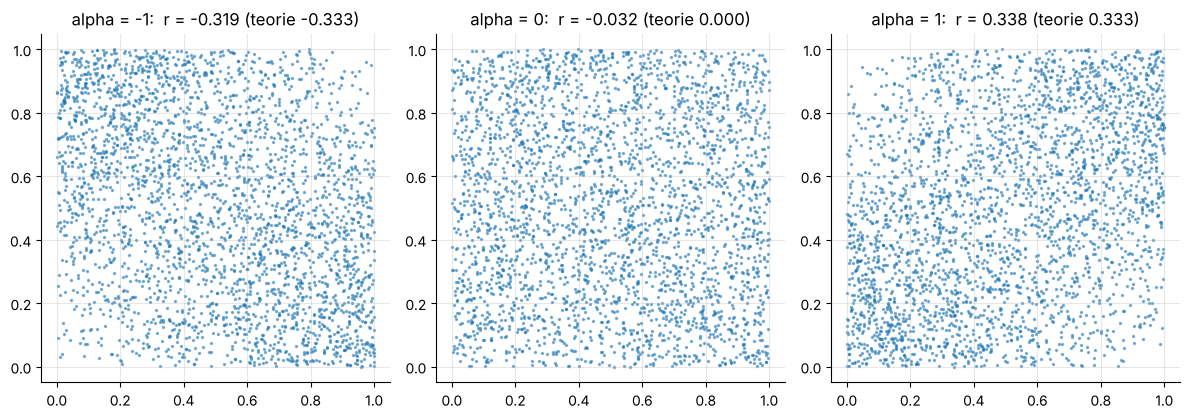

In [2]:
def fgm(alpha, n, rng=RNG):
    x, v = rng.random(n), rng.random(n)
    a = alpha * (2 * x - 1)                    # F(y|x) = (1 - a) y + a y^2 = v
    with np.errstate(invalid='ignore', divide='ignore'):
        y = np.where(np.abs(a) < 1e-12, v, ((a - 1) + np.sqrt((1 - a)**2 + 4 * a * v)) / (2 * a))
    return x, y

fig, axs = plt.subplots(1, 3, figsize=(12, 4))
for ax, alpha in zip(axs, [-1, 0, 1]):
    x, y = fgm(alpha, 3000)
    ax.scatter(x, y, s=2, alpha=0.5)
    ax.set_title(f'alpha = {alpha}:  r = {np.corrcoef(x, y)[0, 1]:.3f} (teorie {alpha / 3:.3f})')
    ax.set_aspect('equal')
plt.tight_layout(); plt.show()

Marginály jsou ve všech třech případech $R(0,1)$, liší se jen struktura závislosti – tu popisuje **kopule**.
FGM kopule umí jen slabou závislost ($|\rho|\le 1/3$), proto se v praxi používají jiné rodiny (oddíl 4).

Totéž s normálními marginály: tři výběry mají (téměř) stejné histogramy obou proměnných, ale velmi odlišné bodové grafy.

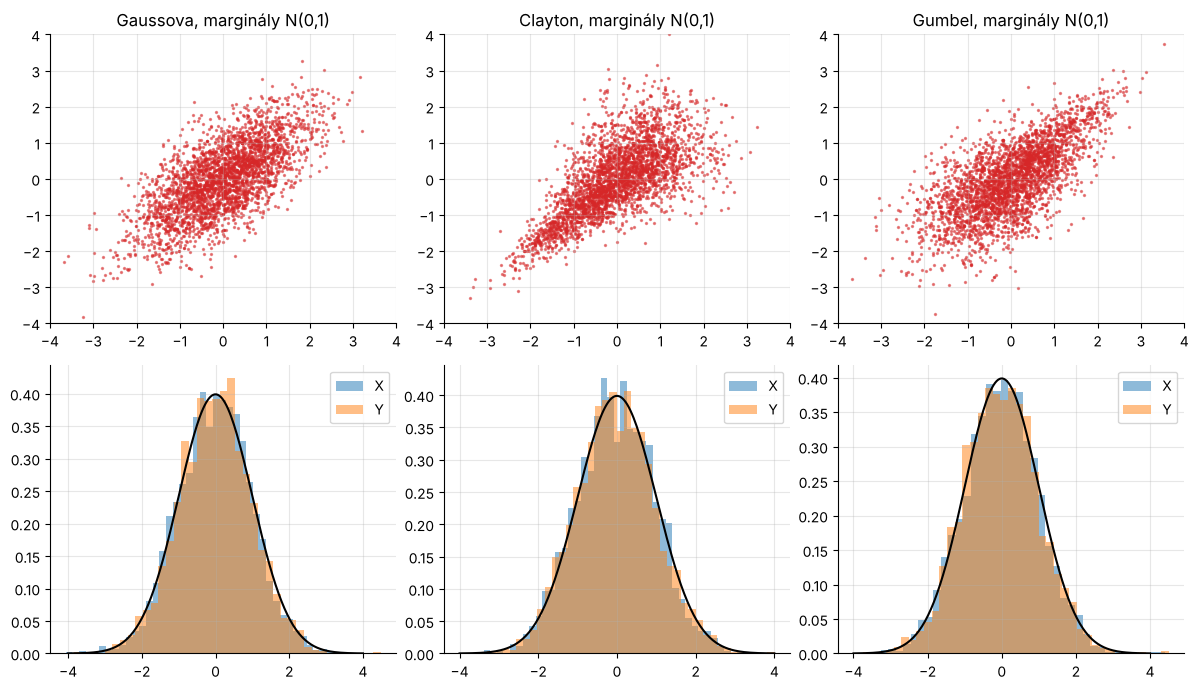

In [3]:
def gauss_cop(rho, n, rng=RNG):
    return stats.norm.cdf(rng.multivariate_normal([0, 0], [[1, rho], [rho, 1]], n))

def clayton(th, n, rng=RNG):          # Marshall-Olkin: gama frailty
    v = rng.gamma(1 / th, 1, n)[:, None]
    return (1 + rng.exponential(size=(n, 2)) / v) ** (-1 / th)

def gumbel(th, n, rng=RNG):           # Marshall-Olkin: pozitivní stabilní rozdělení (Chambers-Mallows-Stuck)
    a = 1 / th
    w = rng.exponential(size=n); T = rng.uniform(0, np.pi, n)
    s = (np.sin(a * T) / np.sin(T)**(1 / a)) * (np.sin((1 - a) * T) / w)**((1 - a) / a)
    return np.exp(-(rng.exponential(size=(n, 2)) / s[:, None])**a)

tau = 0.5
vyb = {'Gaussova': gauss_cop(np.sin(np.pi * tau / 2), 3000),
       'Clayton': clayton(2 * tau / (1 - tau), 3000),
       'Gumbel': gumbel(1 / (1 - tau), 3000)}
fig, axs = plt.subplots(2, 3, figsize=(12, 7))
for j, (name, U) in enumerate(vyb.items()):
    Z = stats.norm.ppf(U)
    axs[0, j].scatter(*Z.T, s=2, alpha=0.5, c='C3'); axs[0, j].set_title(f'{name}, marginály N(0,1)')
    axs[0, j].set_xlim(-4, 4); axs[0, j].set_ylim(-4, 4)
    axs[1, j].hist(Z[:, 0], bins=40, density=True, alpha=0.5, label='X')
    axs[1, j].hist(Z[:, 1], bins=40, density=True, alpha=0.5, label='Y')
    t = np.linspace(-4, 4, 200); axs[1, j].plot(t, stats.norm.pdf(t), 'k'); axs[1, j].legend()
plt.tight_layout(); plt.show()

---
# 2. Základní kopule $\Pi$, $M$, $W$ a Fréchetovy–Hoeffdingovy meze

$$W(u,v)=\max(u+v-1,0)\ \le\ C(u,v)\ \le\ M(u,v)=\min(u,v),\qquad \Pi(u,v)=uv.$$

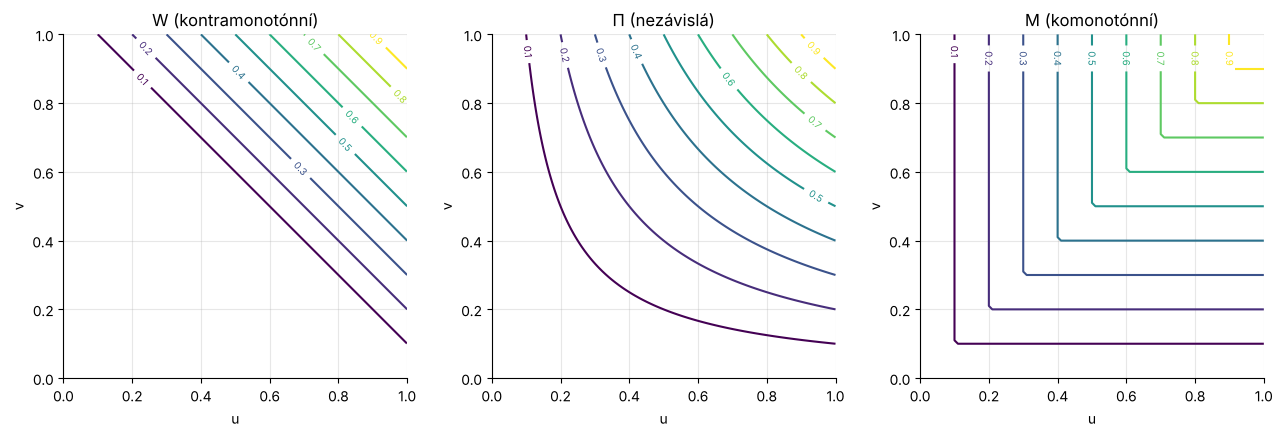

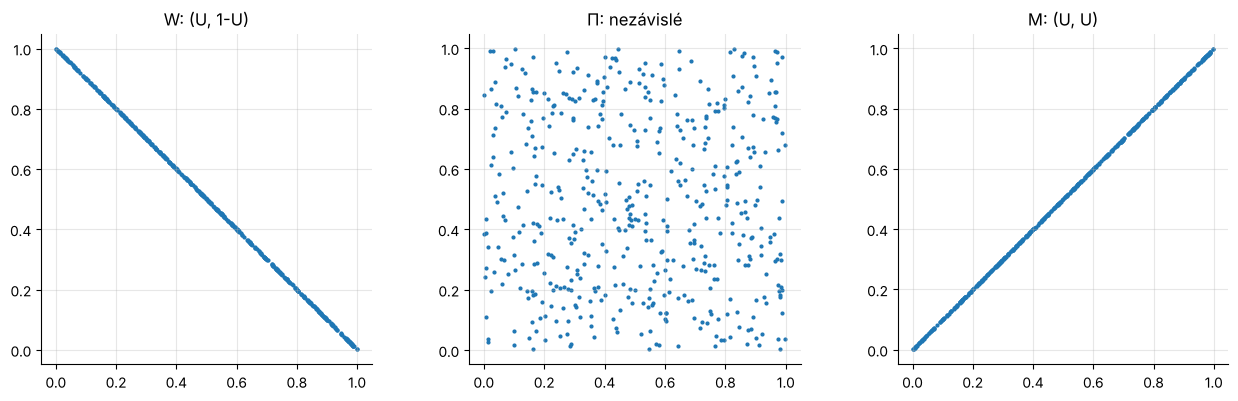

In [4]:
g = np.linspace(0, 1, 101)
uu, vv = np.meshgrid(g, g)
kop = {'W (kontramonotónní)': np.maximum(uu + vv - 1, 0), 'Π (nezávislá)': uu * vv, 'M (komonotónní)': np.minimum(uu, vv)}
fig, axs = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, (name, Cv) in zip(axs, kop.items()):
    cs = ax.contour(uu, vv, Cv, levels=np.arange(0.1, 1, 0.1), cmap='viridis')
    ax.clabel(cs, fontsize=7); ax.set_title(name); ax.set_aspect('equal'); ax.set_xlabel('u'); ax.set_ylabel('v')
plt.tight_layout(); plt.show()

# výběry z W, Π, M
U = RNG.random(500)
fig, axs = plt.subplots(1, 3, figsize=(13, 4))
for ax, (name, (a, b)) in zip(axs, {'W: (U, 1-U)': (U, 1 - U), 'Π: nezávislé': (U, RNG.random(500)), 'M: (U, U)': (U, U)}.items()):
    ax.scatter(a, b, s=4); ax.set_title(name); ax.set_aspect('equal')
plt.tight_layout(); plt.show()

Ověříme, že Gaussova kopule leží mezi mezemi, a že $W$ pro $d=3$ není kopule (kvádr $\langle\frac12,1\rangle^3$ by měl „objem“ $-\frac12$).

In [5]:
u = RNG.uniform(size=(2000, 2))
Cg = stats.multivariate_normal([0, 0], [[1, .7], [.7, 1]]).cdf(stats.norm.ppf(u))
print('W <= C_Gauss:', np.all(Cg >= np.maximum(u.sum(1) - 1, 0) - 1e-9), '  C_Gauss <= M:', np.all(Cg <= u.min(1) + 1e-9))

W3 = lambda a, b, c: max(a + b + c - 2, 0)
vol = (W3(1, 1, 1) - W3(.5, 1, 1) - W3(1, .5, 1) - W3(1, 1, .5)
       + W3(.5, .5, 1) + W3(.5, 1, .5) + W3(1, .5, .5) - W3(.5, .5, .5))
print('"objem" kvádru <1/2,1>^3 pod W pro d = 3:', vol, '=> W není pro d = 3 kopule')

W <= C_Gauss: True   C_Gauss <= M: True
"objem" kvádru <1/2,1>^3 pod W pro d = 3: -0.5 => W není pro d = 3 kopule


---
# 3. Sklarova věta v praxi – pseudo-pozorování

$F(x,y)=C\big(F_X(x),F_Y(y)\big)$. Kopuli dat odhadujeme z **pseudo-pozorování** $\hat u_i=R_i/(n+1)$, $\hat v_i=Q_i/(n+1)$
(pořadí dělená $n+1$) – marginály tím „odstraníme“ a zůstane jen struktura závislosti.

Data: `diabetes` ze `sklearn` (442 pacientů), proměnné `bmi` a `target` (míra progrese nemoci po roce).

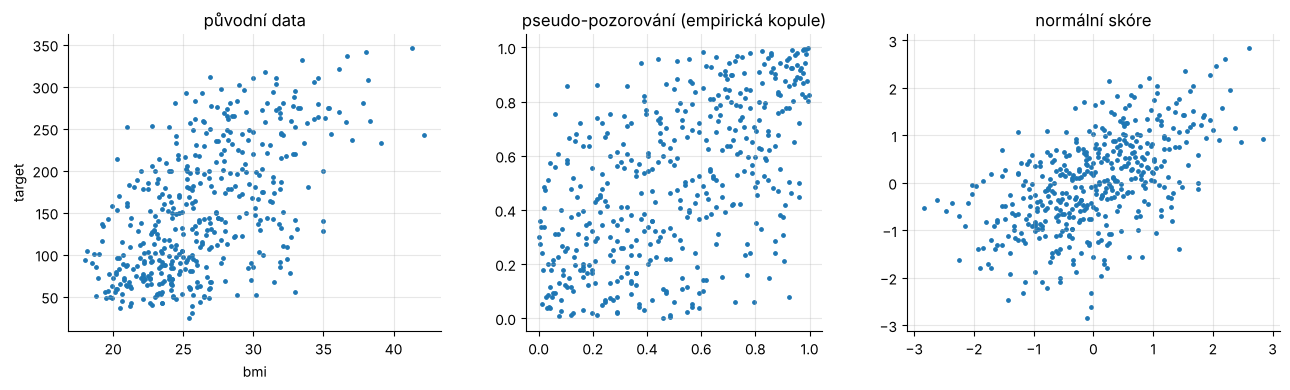

Pearson r = 0.586,  Pearson z pseudo-pozorování = 0.561
Spearman = 0.561,  Kendall tau = 0.391
Pořadové koeficienty se transformací na pseudo-pozorování nezmění: True


In [6]:
d = load_diabetes(as_frame=True, scaled=False).frame
x, y = d['bmi'].to_numpy(), d['target'].to_numpy()
n = len(x)
u_hat = stats.rankdata(x) / (n + 1)
v_hat = stats.rankdata(y) / (n + 1)

fig, axs = plt.subplots(1, 3, figsize=(13, 4))
axs[0].scatter(x, y, s=6); axs[0].set_xlabel('bmi'); axs[0].set_ylabel('target'); axs[0].set_title('původní data')
axs[1].scatter(u_hat, v_hat, s=6); axs[1].set_title('pseudo-pozorování (empirická kopule)'); axs[1].set_aspect('equal')
axs[2].scatter(stats.norm.ppf(u_hat), stats.norm.ppf(v_hat), s=6); axs[2].set_title('normální skóre')
plt.tight_layout(); plt.show()

print(f'Pearson r = {stats.pearsonr(x, y)[0]:.3f},  Pearson z pseudo-pozorování = {stats.pearsonr(u_hat, v_hat)[0]:.3f}')
print(f'Spearman = {stats.spearmanr(x, y)[0]:.3f},  Kendall tau = {stats.kendalltau(x, y)[0]:.3f}')
print('Pořadové koeficienty se transformací na pseudo-pozorování nezmění:',
      np.isclose(stats.kendalltau(x, y)[0], stats.kendalltau(u_hat, v_hat)[0]))

Pearsonův koeficient pseudo-pozorování je právě Spearmanův koeficient. Kendallovo $\tau$ se nezmění vůbec –
závisí jen na pořadí, tedy jen na kopuli.

---
# 4. Parametrické rodiny kopulí

| rodina | $C(u,v)$ | parametr | $\tau$ | chvosty |
|---|---|---|---|---|
| Gaussova | $\Phi_\rho(\Phi^{-1}(u),\Phi^{-1}(v))$ | $\rho\in(-1,1)$ | $\frac2\pi\arcsin\rho$ | žádná závislost |
| $t$ | $t_{\nu,\rho}(t_\nu^{-1}(u),t_\nu^{-1}(v))$ | $\rho,\ \nu$ | $\frac2\pi\arcsin\rho$ | oba, symetricky |
| Clayton | $(u^{-\theta}+v^{-\theta}-1)^{-1/\theta}$ | $\theta>0$ | $\frac{\theta}{\theta+2}$ | dolní |
| Gumbel | $\exp\{-[(-\ln u)^\theta+(-\ln v)^\theta]^{1/\theta}\}$ | $\theta\ge1$ | $1-\frac1\theta$ | horní |
| Frank | $-\frac1\theta\ln\left(1+\frac{(e^{-\theta u}-1)(e^{-\theta v}-1)}{e^{-\theta}-1}\right)$ | $\theta\neq0$ | $1-\frac4\theta\left(1-D_1(\theta)\right)$ | žádná |

$D_1(\theta)=\frac1\theta\int_0^\theta\frac{t}{e^t-1}\,dt$ je Debyeova funkce. Pro práci s daty potřebujeme **hustoty** $c(u,v)=\partial^2C/\partial u\,\partial v$:

In [7]:
def logc_gauss(u, v, rho):
    a, b = stats.norm.ppf(u), stats.norm.ppf(v)
    return -0.5 * np.log(1 - rho**2) - (rho**2 * (a**2 + b**2) - 2 * rho * a * b) / (2 * (1 - rho**2))

def logc_t(u, v, rho, nu):
    a, b = stats.t.ppf(u, nu), stats.t.ppf(v, nu)
    mt = stats.multivariate_t([0, 0], [[1, rho], [rho, 1]], df=nu)
    return mt.logpdf(np.column_stack([a, b])) - stats.t.logpdf(a, nu) - stats.t.logpdf(b, nu)

def logc_clayton(u, v, th):
    return (np.log1p(th) - (th + 1) * (np.log(u) + np.log(v))
            - (2 + 1 / th) * np.log(u**-th + v**-th - 1))

def logc_gumbel(u, v, th):
    x, y = -np.log(u), -np.log(v)
    s = x**th + y**th
    A = s**(1 / th)
    return (-A - np.log(u) - np.log(v) + (th - 1) * (np.log(x) + np.log(y))
            + (1 / th - 2) * np.log(s) + np.log(A + th - 1))

def logc_frank(u, v, th):
    e = np.expm1(-th)
    num = np.log(th * -e) - th * (u + v)
    den = 2 * np.log(np.abs(-e - (-np.expm1(-th * u)) * (-np.expm1(-th * v))))
    return num - den

# kontrola: každá hustota se integruje na 1 (součet přes jemnou mřížku středů čtverců)
m = 1000
g = (np.arange(m) + 0.5) / m
Ug, Vg = [a.ravel() for a in np.meshgrid(g, g)]
for name, lc in {'Gauss rho=0.7': logc_gauss(Ug, Vg, 0.7), 't rho=0.7, nu=4': logc_t(Ug, Vg, 0.7, 4),
                 'Clayton th=2': logc_clayton(Ug, Vg, 2.0), 'Gumbel th=2': logc_gumbel(Ug, Vg, 2.0),
                 'Frank th=5.74': logc_frank(Ug, Vg, 5.74)}.items():
    print(f'{name:18s} integrál hustoty ≈ {np.exp(lc).mean():.4f}')

Gauss rho=0.7      integrál hustoty ≈ 1.0000
t rho=0.7, nu=4    integrál hustoty ≈ 1.0002
Clayton th=2       integrál hustoty ≈ 1.0003
Gumbel th=2        integrál hustoty ≈ 1.0002
Frank th=5.74      integrál hustoty ≈ 1.0000


Vrstevnice sdružené hustoty $f(x,y)=c\big(\Phi(x),\Phi(y)\big)\varphi(x)\varphi(y)$ – všechny kopule mají $\tau=0{,}5$
a obě marginály $N(0,1)$. Jen Gaussova kopule dává eliptické vrstevnice (dvourozměrné normální rozdělení).

tau = 0.5:  Gauss rho = 0.707, t rho = 0.707, Clayton theta = 2.000, Gumbel theta = 2.000, Frank theta = 5.736


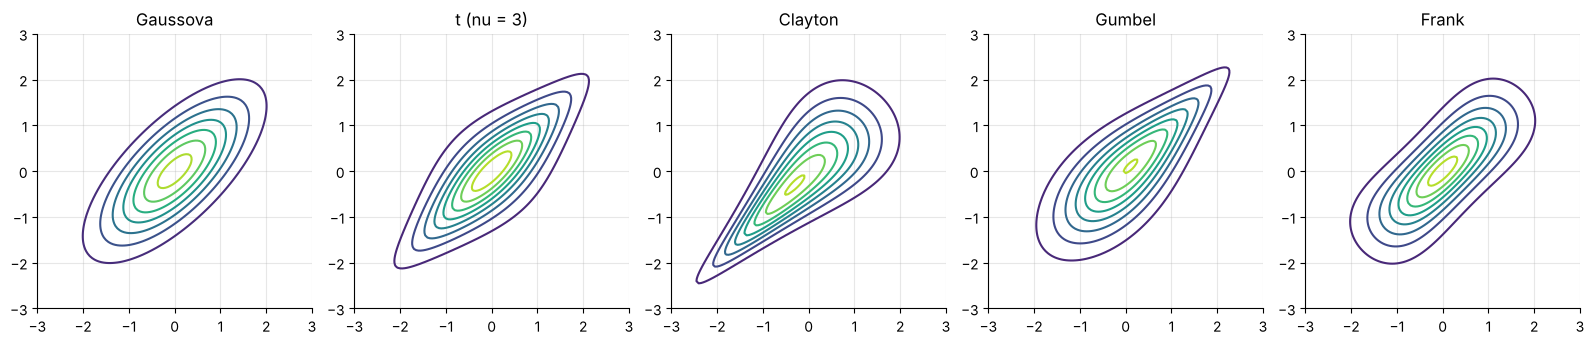

In [8]:
def frank_theta(tau):
    D1 = lambda th: integrate.quad(lambda t: t / np.expm1(t), 0, th)[0] / th
    return optimize.brentq(lambda th: 1 - 4 / th * (1 - D1(th)) - tau, 1e-3, 100)

tau = 0.5
th_c, th_g, th_f, rho_e = 2 * tau / (1 - tau), 1 / (1 - tau), frank_theta(tau), np.sin(np.pi * tau / 2)
print(f'tau = 0.5:  Gauss rho = {rho_e:.3f}, t rho = {rho_e:.3f}, Clayton theta = {th_c:.3f}, '
      f'Gumbel theta = {th_g:.3f}, Frank theta = {th_f:.3f}')

g = np.linspace(-3, 3, 121)
X, Y = np.meshgrid(g, g)
Uu, Vv = stats.norm.cdf(X), stats.norm.cdf(Y)
logm = stats.norm.logpdf(X) + stats.norm.logpdf(Y)
dens = {'Gaussova': logc_gauss(Uu, Vv, rho_e),
        't (nu = 3)': logc_t(Uu.ravel(), Vv.ravel(), rho_e, 3).reshape(X.shape),
        'Clayton': logc_clayton(Uu, Vv, th_c),
        'Gumbel': logc_gumbel(Uu, Vv, th_g),
        'Frank': logc_frank(Uu, Vv, th_f)}
fig, axs = plt.subplots(1, 5, figsize=(16, 3.6))
for ax, (name, lc) in zip(axs, dens.items()):
    ax.contour(X, Y, np.exp(lc + logm), levels=8, cmap='viridis')
    ax.set_title(name); ax.set_aspect('equal')
plt.tight_layout(); plt.show()

Clayton má vrstevnice „protažené“ do levého dolního rohu (společné malé hodnoty), Gumbel do pravého horního,
$t$-kopule do obou rohů, Frank je naopak v rozích „sevřenější“ než Gaussova.

---
# 5. Kopule a pořadové míry závislosti

$\tau=4\,\E\,C(U,V)-1$ a $\rho_S=12\int\!\!\int C(u,v)\,du\,dv-3$ závisejí **jen na kopuli**. Pearsonův $\rho$ závisí i na marginálách.

### 5.1 Ověření vzorců pro $\tau$ simulací (Marshallův–Olkinův algoritmus)

In [9]:
rows = []
for th in [0.5, 2, 6]:
    U = clayton(th, 100_000)
    rows.append({'rodina': 'Clayton', 'theta': th, 'tau teorie': th / (th + 2), 'tau simulace': stats.kendalltau(*U.T)[0],
                 '4 E C(U,V) - 1': 4 * np.mean((U[:, 0]**-th + U[:, 1]**-th - 1)**(-1 / th)) - 1})
for th in [1.5, 2, 4]:
    U = gumbel(th, 100_000)
    Cg = np.exp(-((-np.log(U[:, 0]))**th + (-np.log(U[:, 1]))**th)**(1 / th))
    rows.append({'rodina': 'Gumbel', 'theta': th, 'tau teorie': 1 - 1 / th, 'tau simulace': stats.kendalltau(*U.T)[0],
                 '4 E C(U,V) - 1': 4 * Cg.mean() - 1})
pd.DataFrame(rows).round(3)

,rodina,theta,tau teorie,tau simulace,"4 E C(U,V) - 1"
0,Clayton,0.5,0.200,0.199,0.202
1,Clayton,2.0,0.500,0.498,0.507
2,Clayton,6.0,0.750,0.750,0.752
3,Gumbel,1.5,0.333,0.335,0.336
4,Gumbel,2.0,0.500,0.501,0.497
5,Gumbel,4.0,0.750,0.750,0.748


### 5.2 Invariance $\tau$ a $\rho_S$ vůči marginálám

Gaussova kopule s $\rho=0{,}7$, tři různé dvojice marginál. Pro lognormální marginály s rozdílným rozptylem nedosáhne Pearsonův
koeficient ani teoretického maxima 1 – maximum je dané komonotónní kopulí $M$ (Fréchetova horní mez).

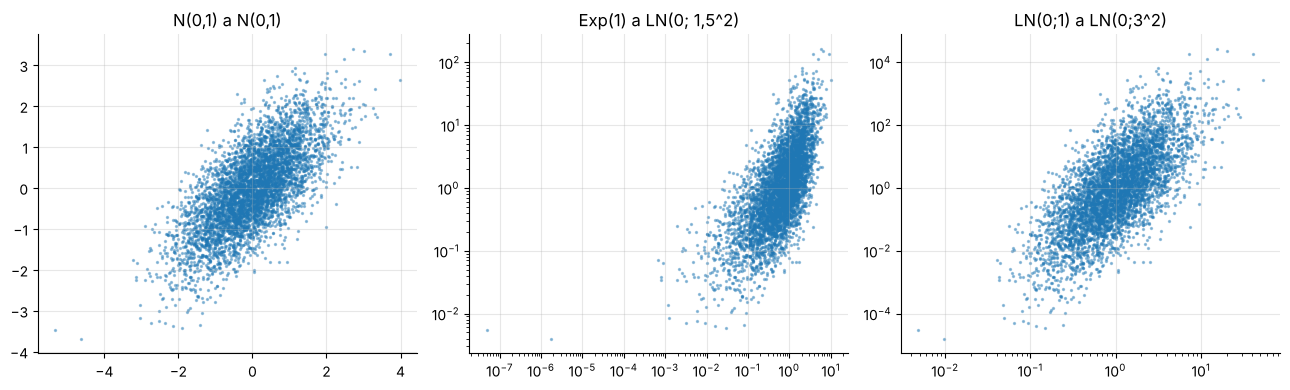

            marginály  Pearson  Spearman  Kendall
      N(0,1) a N(0,1)    0.701     0.685    0.495
Exp(1) a LN(0; 1,5^2)    0.498     0.685    0.495
  LN(0;1) a LN(0;3^2)    0.338     0.685    0.495
teorie: tau = 0.494  rho_S = 0.683
LN(0,1) a LN(0,1^2): největší dosažitelná Pearsonova korelace = 1.000
LN(0,1) a LN(0,2^2): největší dosažitelná Pearsonova korelace = 0.666
LN(0,1) a LN(0,3^2): největší dosažitelná Pearsonova korelace = 0.162


In [10]:
rho, n = 0.7, 5000
Z = RNG.multivariate_normal([0, 0], [[1, rho], [rho, 1]], n)
U = stats.norm.cdf(Z)
marg = {'N(0,1) a N(0,1)': (Z[:, 0], Z[:, 1]),
        'Exp(1) a LN(0; 1,5^2)': (stats.expon.ppf(U[:, 0]), stats.lognorm.ppf(U[:, 1], s=1.5)),
        'LN(0;1) a LN(0;3^2)': (stats.lognorm.ppf(U[:, 0], s=1), stats.lognorm.ppf(U[:, 1], s=3))}
rows = []
fig, axs = plt.subplots(1, 3, figsize=(13, 4))
for ax, (name, (X_, Y_)) in zip(axs, marg.items()):
    rows.append({'marginály': name, 'Pearson': np.corrcoef(X_, Y_)[0, 1],
                 'Spearman': stats.spearmanr(X_, Y_)[0], 'Kendall': stats.kendalltau(X_, Y_)[0]})
    ax.scatter(X_, Y_, s=2, alpha=0.4); ax.set_title(name)
    if 'LN' in name: ax.set_xscale('log'); ax.set_yscale('log')
plt.tight_layout(); plt.show()
print(pd.DataFrame(rows).round(3).to_string(index=False))
print('teorie: tau =', round(2 / np.pi * np.arcsin(rho), 3), ' rho_S =', round(6 / np.pi * np.arcsin(rho / 2), 3))
for s in [1, 2, 3]:
    rho_max = (np.exp(s) - 1) / np.sqrt((np.e - 1) * (np.exp(s**2) - 1))
    print(f'LN(0,1) a LN(0,{s}^2): největší dosažitelná Pearsonova korelace = {rho_max:.3f}')

---
# 6. Závislost v chvostech

$$\lambda_L=\lim_{q\to0^+}\P(V\le q\mid U\le q)=\lim_{q\to0^+}\frac{C(q,q)}{q},\qquad
\lambda_U=\lim_{q\to0^+}\P(V>1-q\mid U>1-q).$$

Teorie: Clayton $\lambda_L=2^{-1/\theta}$, Gumbel $\lambda_U=2-2^{1/\theta}$, $t$-kopule $\lambda_L=\lambda_U=2\,t_{\nu+1}\!\left(-\sqrt{\frac{(\nu+1)(1-\rho)}{1+\rho}}\right)$,
Gaussova a Frank $\lambda=0$.

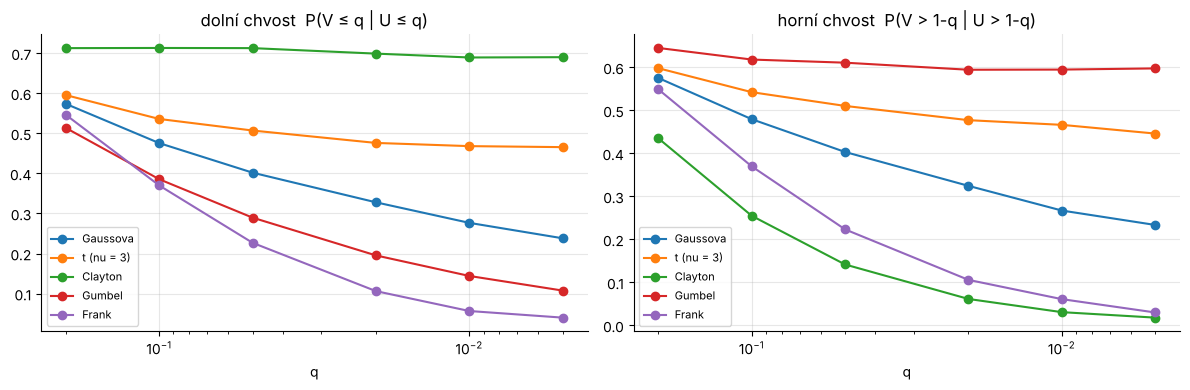

,kopule,tau,"P(V<=q|U<=q), q=0.005",lambda_L teorie,"P(V>1-q|U>1-q), q=0.005",lambda_U teorie
0,Gaussova,0.497,0.238,0.000,0.233,0.000
1,t (nu = 3),0.498,0.466,0.454,0.446,0.454
2,Clayton,0.509,0.690,0.707,0.018,0.000
3,Gumbel,0.501,0.108,0.000,0.598,0.586
4,Frank,0.489,0.040,0.000,0.030,0.000


In [11]:
def t_cop(rho, nu, n, rng=RNG):
    Z = rng.multivariate_normal([0, 0], [[1, rho], [rho, 1]], n)
    W = rng.chisquare(nu, n)[:, None]
    return stats.t.cdf(Z / np.sqrt(W / nu), nu)

def frank_cond(th, n, rng=RNG):          # podmíněná metoda (oddíl 7)
    u, w = rng.random(n), rng.random(n)
    v = -np.log1p(w * np.expm1(-th) / (w + (1 - w) * np.exp(-th * u))) / th
    return np.column_stack([u, v])

nbig = 400_000
tau = 0.5
vyb = {'Gaussova': gauss_cop(rho_e, nbig), 't (nu = 3)': t_cop(rho_e, 3, nbig),
       'Clayton': clayton(th_c, nbig), 'Gumbel': gumbel(th_g, nbig), 'Frank': frank_cond(th_f, nbig)}
lam_t = 2 * stats.t.cdf(-np.sqrt(4 * (1 - rho_e) / (1 + rho_e)), 4)
teorie = {'Gaussova': (0, 0), 't (nu = 3)': (lam_t, lam_t), 'Clayton': (2**(-1 / th_c), 0),
          'Gumbel': (0, 2 - 2**(1 / th_g)), 'Frank': (0, 0)}
qs = np.array([0.2, 0.1, 0.05, 0.02, 0.01, 0.005])
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
rows = []
for name, U in vyb.items():
    lo = [np.mean((U[:, 0] <= q) & (U[:, 1] <= q)) / q for q in qs]
    up = [np.mean((U[:, 0] > 1 - q) & (U[:, 1] > 1 - q)) / q for q in qs]
    axs[0].plot(qs, lo, 'o-', label=name); axs[1].plot(qs, up, 'o-', label=name)
    rows.append({'kopule': name, 'tau': stats.kendalltau(*U[:5000].T)[0], 'P(V<=q|U<=q), q=0.005': lo[-1],
                 'lambda_L teorie': teorie[name][0], 'P(V>1-q|U>1-q), q=0.005': up[-1], 'lambda_U teorie': teorie[name][1]})
for ax, t_ in zip(axs, ['dolní chvost  P(V ≤ q | U ≤ q)', 'horní chvost  P(V > 1-q | U > 1-q)']):
    ax.set_xscale('log'); ax.invert_xaxis(); ax.set_xlabel('q'); ax.set_title(t_); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
pd.DataFrame(rows).round(3)

Všech pět kopulí má stejné $\tau=0{,}5$, ale pravděpodobnost současného extrému se s $q\to0$ chová úplně jinak:
u Frankovy kopule rychle klesá k nule, u Gaussovy také k nule, ale **velmi pomalu** (při $q=0{,}005$ je stále kolem $0{,}23$),
u Claytona (dolní chvost), Gumbela (horní chvost) a $t$-kopule (oba) se ustálí na kladné limitě $\lambda$.
Pro malé $q$ jsou odhady zatížené náhodnou chybou – i proto se závislost chvostů z dat odhaduje obtížně.

---
# 7. Generování výběrů

### 7.1 Podmíněná metoda

$h(v\,|\,u)=\partial C(u,v)/\partial u$ je podmíněná distribuční funkce $V$ při $U=u$. Vygenerujeme $U,W\sim R(0,1)$
nezávisle a položíme $V=h^{-1}(W\,|\,U)$. Pro Claytona a Franka je inverze explicitní:

* Clayton: $V=\left[U^{-\theta}\left(W^{-\theta/(1+\theta)}-1\right)+1\right]^{-1/\theta}$,
* Frank: $V=-\frac1\theta\ln\left(1+\frac{W\,(e^{-\theta}-1)}{W+(1-W)\,e^{-\theta U}}\right)$.

Clayton theta = 2: tau podmíněná metoda = 0.513, Marshall-Olkin = 0.504, teorie = 0.500
Dvouvýběrový KS test pro součin U*V (shoda obou algoritmů): p = 0.44


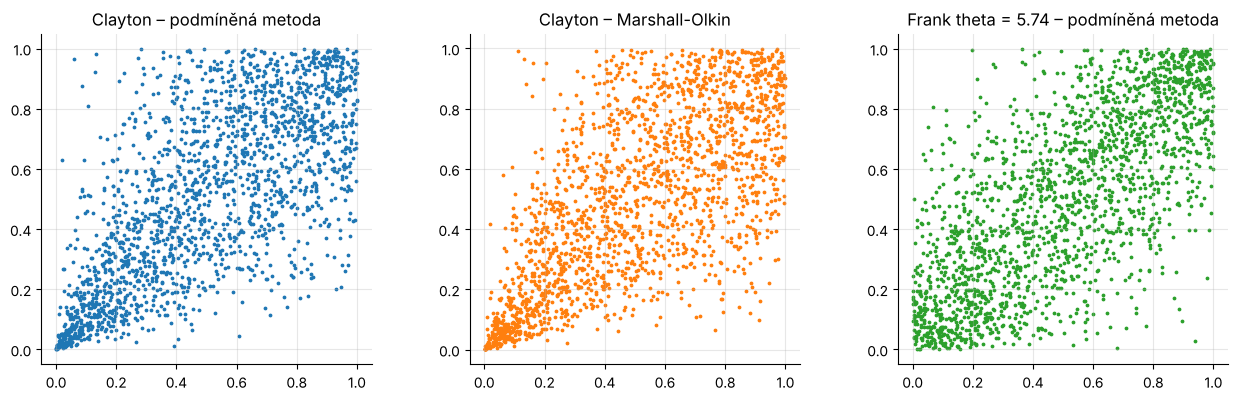

In [12]:
def clayton_cond(th, n, rng=RNG):
    u, w = rng.random(n), rng.random(n)
    v = (u**-th * (w**(-th / (1 + th)) - 1) + 1)**(-1 / th)
    return np.column_stack([u, v])

th = 2.0
A, B = clayton_cond(th, 20000), clayton(th, 20000)
print(f'Clayton theta = 2: tau podmíněná metoda = {stats.kendalltau(*A[:5000].T)[0]:.3f}, '
      f'Marshall-Olkin = {stats.kendalltau(*B[:5000].T)[0]:.3f}, teorie = {th / (th + 2):.3f}')
print('Dvouvýběrový KS test pro součin U*V (shoda obou algoritmů): p =',
      round(stats.ks_2samp(A.prod(1), B.prod(1)).pvalue, 3))

fig, axs = plt.subplots(1, 3, figsize=(13, 4))
axs[0].scatter(*A[:2000].T, s=3); axs[0].set_title('Clayton – podmíněná metoda')
axs[1].scatter(*B[:2000].T, s=3, c='C1'); axs[1].set_title('Clayton – Marshall-Olkin')
F = frank_cond(th_f, 2000); axs[2].scatter(*F.T, s=3, c='C2'); axs[2].set_title(f'Frank theta = {th_f:.2f} – podmíněná metoda')
for ax in axs: ax.set_aspect('equal')
plt.tight_layout(); plt.show()

### 7.2 Od kopule k datům s libovolnými marginály

Po vygenerování $(U,V)$ z kopule dostaneme data s požadovanými marginály jako $X=F_X^{-1}(U)$, $Y=F_Y^{-1}(V)$.
Příklad: průtoky dvou přítoků řeky (Gumbelovo rozdělení maxim) s horní závislostí v chvostech (Gumbelova kopule).

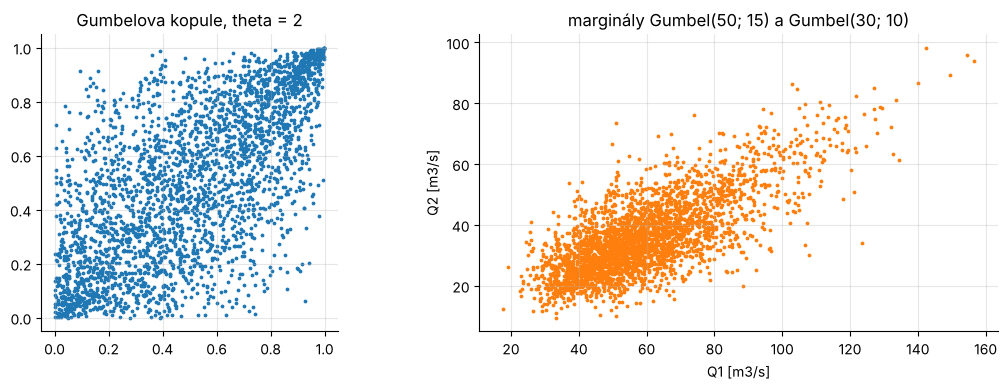

Kendall tau: kopule 0.495, průtoky 0.495 (stejné)


In [13]:
U = gumbel(2.0, 3000)
Q1 = stats.gumbel_r.ppf(U[:, 0], loc=50, scale=15)     # průtok 1 [m3/s]
Q2 = stats.gumbel_r.ppf(U[:, 1], loc=30, scale=10)     # průtok 2 [m3/s]
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
axs[0].scatter(*U.T, s=3); axs[0].set_title('Gumbelova kopule, theta = 2'); axs[0].set_aspect('equal')
axs[1].scatter(Q1, Q2, s=3, c='C1'); axs[1].set_xlabel('Q1 [m3/s]'); axs[1].set_ylabel('Q2 [m3/s]')
axs[1].set_title('marginály Gumbel(50; 15) a Gumbel(30; 10)')
plt.tight_layout(); plt.show()
print(f'Kendall tau: kopule {stats.kendalltau(*U.T)[0]:.3f}, průtoky {stats.kendalltau(Q1, Q2)[0]:.3f} (stejné)')

---
# 8. Odhad kopule z dat a výběr rodiny

Postup (metoda pseudo-věrohodnosti):

1. pseudo-pozorování $\hat u_i=R_i/(n+1)$, $\hat v_i=Q_i/(n+1)$,
2. počáteční odhad parametru z $\hat\tau$ (inverze vzorců z oddílu 4),
3. maximalizace $\ell(\theta)=\sum_i\ln c(\hat u_i,\hat v_i;\theta)$,
4. porovnání rodin pomocí AIC $=-2\ell+2p$.

Nejprve na simulovaných datech, kde skutečnou kopuli známe (Gumbel, $\theta=2$, nenormální marginály):

In [14]:
def fit_copulas(u, v):
    tau_hat = stats.kendalltau(u, v)[0]
    res = {}
    neg = lambda f: (lambda p: -np.sum(f(u, v, p)))
    r = optimize.minimize_scalar(neg(logc_gauss), bounds=(-0.99, 0.99), method='bounded')
    res['Gaussova'] = (r.x, -r.fun, 1)
    best = None
    for nu in [2, 3, 4, 6, 8, 12, 20, 30]:
        r = optimize.minimize_scalar(lambda p: -np.sum(logc_t(u, v, p, nu)), bounds=(-0.99, 0.99), method='bounded')
        if best is None or -r.fun > best[1]:
            best = ((round(r.x, 3), nu), -r.fun, 2)
    res['t'] = best
    if tau_hat > 0:
        r = optimize.minimize_scalar(neg(logc_clayton), bounds=(1e-3, 30), method='bounded'); res['Clayton'] = (r.x, -r.fun, 1)
        r = optimize.minimize_scalar(neg(logc_gumbel), bounds=(1.0001, 30), method='bounded'); res['Gumbel'] = (r.x, -r.fun, 1)
    r = optimize.minimize_scalar(neg(logc_frank), bounds=(-40, 40), method='bounded'); res['Frank'] = (r.x, -r.fun, 1)
    tab = pd.DataFrame([{'kopule': k, 'parametr': p, 'log-věrohodnost': ll, 'AIC': -2 * ll + 2 * k_}
                        for k, (p, ll, k_) in res.items()]).sort_values('AIC')
    return tau_hat, tab

U = gumbel(2.0, 800)
xs, ys = stats.expon.ppf(U[:, 0]), stats.lognorm.ppf(U[:, 1], s=0.8)
u_hat, v_hat = stats.rankdata(xs) / 801, stats.rankdata(ys) / 801
tau_hat, tab = fit_copulas(u_hat, v_hat)
print(f'tau = {tau_hat:.3f}  ->  Gumbel theta z tau = {1 / (1 - tau_hat):.3f} (skutečné theta = 2)')
tab.round(3)

tau = 0.529  ->  Gumbel theta z tau = 2.124 (skutečné theta = 2)


,kopule,parametr,log-věrohodnost,AIC
3,Gumbel,2.107964,330.110,-658.220
1,t,"(0.734, 8)",309.663,-615.325
0,Gaussova,0.733564,304.938,-607.876
4,Frank,6.281336,284.666,-567.333
2,Clayton,1.18221,185.023,-368.045


AIC správně vybere Gumbelovu kopuli a odhad parametru je blízko skutečné hodnotě 2.

### Reálná data: `bmi` a `target` (diabetes)

n = 442, tau = 0.391


,kopule,parametr,log-věrohodnost,AIC
3,Gumbel,1.572128,83.058,-164.116
0,Gaussova,0.560499,80.814,-159.628
4,Frank,3.983352,80.182,-158.364
1,t,"(0.56, 30)",80.184,-156.367
2,Clayton,0.663889,42.028,-82.055


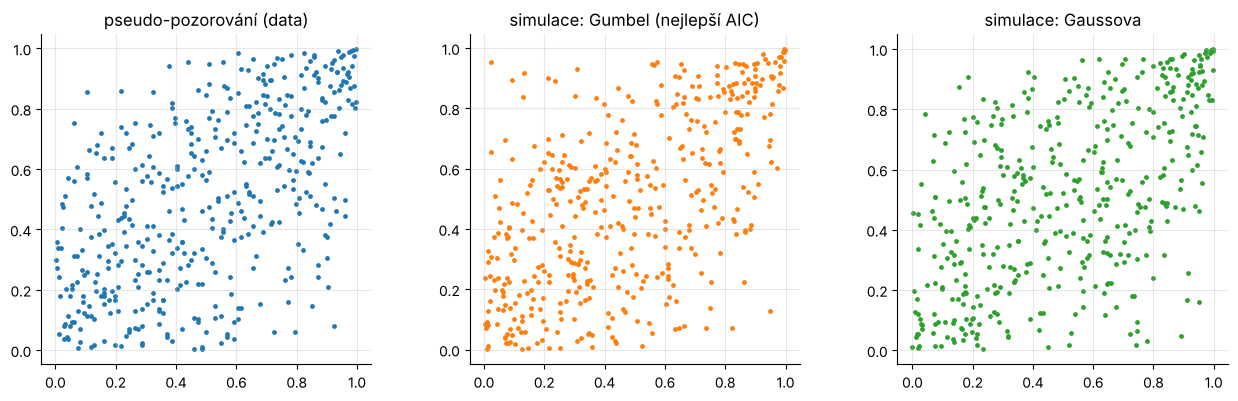

In [15]:
x, y = d['bmi'].to_numpy(), d['target'].to_numpy()
n = len(x)
u_hat, v_hat = stats.rankdata(x) / (n + 1), stats.rankdata(y) / (n + 1)
tau_hat, tab = fit_copulas(u_hat, v_hat)
print(f'n = {n}, tau = {tau_hat:.3f}')
display(tab.round(3))

# porovnání: empirická kopule vs. výběr z nejlepší a z Gaussovy kopule
best = tab.iloc[0]['kopule']
sim = {'Clayton': lambda p: clayton(p, n), 'Gumbel': lambda p: gumbel(p, n),
       'Frank': lambda p: frank_cond(p, n), 'Gaussova': lambda p: gauss_cop(p, n),
       't': lambda p: t_cop(p[0], p[1], n)}
p_best = tab.iloc[0]['parametr']
p_gauss = tab.set_index('kopule').loc['Gaussova', 'parametr']
fig, axs = plt.subplots(1, 3, figsize=(13, 4))
axs[0].scatter(u_hat, v_hat, s=6); axs[0].set_title('pseudo-pozorování (data)')
Ub = sim[best](p_best); axs[1].scatter(*Ub.T, s=6, c='C1'); axs[1].set_title(f'simulace: {best} (nejlepší AIC)')
Ug = sim['Gaussova'](p_gauss); axs[2].scatter(*Ug.T, s=6, c='C2'); axs[2].set_title('simulace: Gaussova')
for ax in axs: ax.set_aspect('equal')
plt.tight_layout(); plt.show()

Rozdíly AIC mezi rodinami bývají u reálných dat malé – při $n$ v řádu stovek se jednotlivé rodiny od sebe obtížně
rozlišují, a výběr kopule by proto měl vycházet i z věcné úvahy (očekáváme společné extrémy? v kterém chvostu?).

### Graf $K$-funkce (Kendallova distribuční funkce)

Pro Archimédovy kopule je $K(t)=\P\big(C(U,V)\le t\big)=t-\psi(t)/\psi'(t)$. Empiricky ji odhadneme z $\hat w_i=\frac{1}{n-1}\#\{j:\hat u_j<\hat u_i,\ \hat v_j<\hat v_i\}$
a porovnáme s teoretickými křivkami – jednoduchý grafický test volby rodiny.

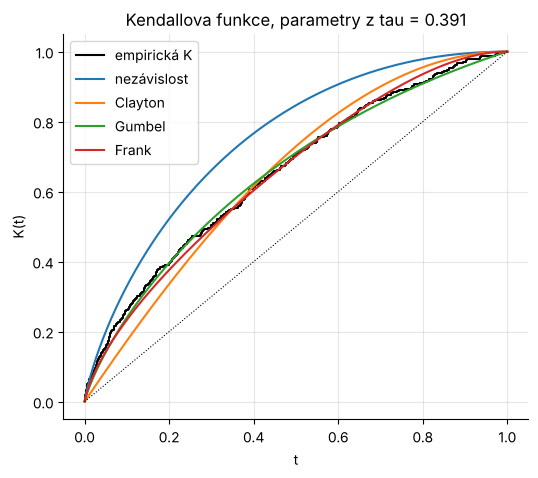

In [16]:
def K_emp(u, v):
    w = np.array([np.mean((u < ui) & (v < vi)) for ui, vi in zip(u, v)]) * len(u) / (len(u) - 1)
    return np.sort(w)

t = np.linspace(1e-4, 1, 300)
th_c_hat = 2 * tau_hat / (1 - tau_hat); th_g_hat = 1 / (1 - tau_hat); th_f_hat = frank_theta(tau_hat)
K = {'nezávislost': t - t * np.log(t),
     'Clayton': t + t * (1 - t**th_c_hat) / th_c_hat,
     'Gumbel': t - t * np.log(t) / th_g_hat,
     'Frank': t - np.log(np.expm1(-th_f_hat * t) / np.expm1(-th_f_hat)) * np.expm1(th_f_hat * t) / th_f_hat}
w = K_emp(u_hat, v_hat)
plt.figure(figsize=(6, 5))
plt.step(w, np.arange(1, len(w) + 1) / len(w), 'k', where='post', label='empirická K')
for name, Kt in K.items():
    plt.plot(t, Kt, label=f'{name}')
plt.plot([0, 1], [0, 1], 'k:', lw=0.8); plt.xlabel('t'); plt.ylabel('K(t)'); plt.legend()
plt.title(f'Kendallova funkce, parametry z tau = {tau_hat:.3f}'); plt.show()

---
# 9. Proč na kopuli záleží – pravděpodobnost současných extrémů

Dvě veličiny (např. průtoky dvou přítoků, ztráty dvou pojistných portfolií) se stejnými marginály a stejným $\tau=0{,}5$.
Jaká je pravděpodobnost, že **obě současně** překročí svůj 99% kvantil? Při jednom pozorování za rok jde u každé
veličiny zvlášť o stoletou událost; doba návratu současného překročení je $1/p$ let.

,kopule,P(obě > 99% kvantil),násobek oproti nezávislosti,doba návratu [roky]
0,nezávislost,0.00011,1.06,9433.96226
1,Gaussova,0.00273,27.29,366.43459
2,t (nu = 3),0.00463,46.31,215.93608
3,Clayton,0.00029,2.87,3484.32056
4,Gumbel,0.00593,59.28,168.69096
5,Frank,0.00053,5.34,1872.65918


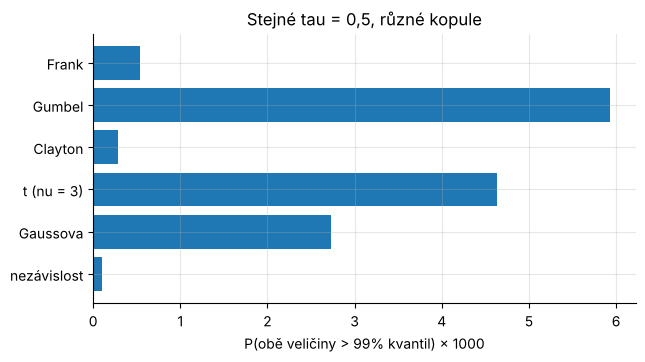

In [17]:
nbig = 1_000_000
rows = []
for name, U in {'nezávislost': RNG.random((nbig, 2)), 'Gaussova': gauss_cop(rho_e, nbig),
                't (nu = 3)': t_cop(rho_e, 3, nbig), 'Clayton': clayton(th_c, nbig),
                'Gumbel': gumbel(th_g, nbig), 'Frank': frank_cond(th_f, nbig)}.items():
    p = np.mean((U[:, 0] > 0.99) & (U[:, 1] > 0.99))
    rows.append({'kopule': name, 'P(obě > 99% kvantil)': p, 'násobek oproti nezávislosti': p / 1e-4,
                 'doba návratu [roky]': 1 / p})
tab9 = pd.DataFrame(rows)
display(tab9.round(5))
plt.figure(figsize=(7, 3.5))
plt.barh(tab9['kopule'], tab9['P(obě > 99% kvantil)'] * 1000)
plt.xlabel('P(obě veličiny > 99% kvantil) × 1000'); plt.title('Stejné tau = 0,5, různé kopule'); plt.show()

Při nezávislosti je pravděpodobnost $0{,}01^2=10^{-4}$ (doba návratu 10 000 let). Se závislostí $\tau=0{,}5$ je mnohem větší
a mezi kopulemi se liší až dvacetinásobně: Gumbelova a $t$-kopule (horní závislost v chvostech) dávají nejvyšší riziko
současného extrému, Gaussova menší, Frankova a Claytonova (ta má závislost jen v dolním chvostu) výrazně menší. Pokud by se riziko počítalo z Gaussovy kopule a skutečnost odpovídala Gumbelově, bylo by výrazně podceněno.

---
# 10. Praktická ukázka – kopule pro výnosy akciových indexů

Data `EuStockMarkets` (balík R *datasets*): denní uzavírací hodnoty indexů DAX (Německo), SMI (Švýcarsko), CAC (Francie) a FTSE (Velká Británie)
v letech 1991–1998, 1860 obchodních dní. Budeme modelovat **denní logaritmické výnosy** (v %) indexů DAX a CAC:
$r_t=100\,\ln(P_t/P_{t-1})$.

**Postup analýzy pomocí kopule (Sklarova věta v praxi):**

1. příprava a popis dat – čištění, grafy, korelace, pseudo-pozorování,
2. model **marginál** (každý index zvlášť),
3. výběr a odhad **kopule** z pseudo-pozorování (AIC),
4. kontrola – sedí závislost v chvostech?
5. **použití** – simulace ze složeného modelu: riziko portfolia, pravděpodobnost současného propadu.

Data načteme ze souboru `EuStockMarkets.csv` (přiložen k přednášce), případně je stáhneme funkcí `statsmodels.api.datasets.get_rdataset`.

vyřazeno 117 dní s nulovým výnosem DAX nebo CAC, zbývá n = 1742 dní


,průměr,sm. odch.,min,max,šikmost,špičatost (excess)
DAX,0.065,1.030,-9.628,5.076,-0.555,6.300
SMI,0.082,0.925,-8.383,4.968,-0.633,5.755
CAC,0.044,1.103,-7.575,6.098,-0.178,2.395
FTSE,0.043,0.796,-4.140,5.440,0.110,2.650


DAX-CAC: Pearson r = 0.747, Spearman = 0.711, Kendall tau = 0.525


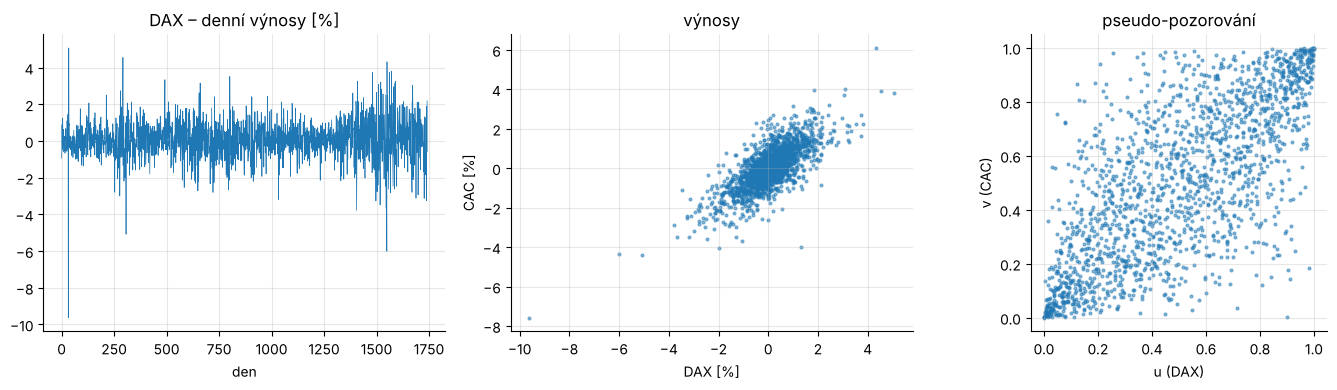

In [18]:
import statsmodels.api as sm
try:
    eu = pd.read_csv('EuStockMarkets.csv')
except FileNotFoundError:
    eu = sm.datasets.get_rdataset('EuStockMarkets').data      # vyžaduje internet
R = 100 * np.log(eu).diff().dropna()                           # denní log-výnosy v %
# svátky: hodnota indexu je v datech zkopírována z předchozího dne -> nulový výnos (shody v pořadích)
ok = (R['DAX'] != 0) & (R['CAC'] != 0)
x, y = R.loc[ok, 'DAX'].to_numpy(), R.loc[ok, 'CAC'].to_numpy()
n = len(x)
print(f'vyřazeno {(~ok).sum()} dní s nulovým výnosem DAX nebo CAC, zbývá n = {n} dní')
display(pd.DataFrame({'průměr': R.mean(), 'sm. odch.': R.std(), 'min': R.min(), 'max': R.max(),
                      'šikmost': R.skew(), 'špičatost (excess)': R.kurt()}).round(3))
print(f'DAX-CAC: Pearson r = {np.corrcoef(x, y)[0, 1]:.3f}, Spearman = {stats.spearmanr(x, y)[0]:.3f}, '
      f'Kendall tau = {stats.kendalltau(x, y)[0]:.3f}')

u_hat, v_hat = stats.rankdata(x) / (n + 1), stats.rankdata(y) / (n + 1)   # pseudo-pozorování
fig, axs = plt.subplots(1, 3, figsize=(14, 4))
axs[0].plot(x, lw=0.5); axs[0].set_title('DAX – denní výnosy [%]'); axs[0].set_xlabel('den')
axs[1].scatter(x, y, s=4, alpha=0.5); axs[1].set_xlabel('DAX [%]'); axs[1].set_ylabel('CAC [%]'); axs[1].set_title('výnosy')
axs[2].scatter(u_hat, v_hat, s=4, alpha=0.5); axs[2].set_xlabel('u (DAX)'); axs[2].set_ylabel('v (CAC)')
axs[2].set_title('pseudo-pozorování'); axs[2].set_aspect('equal')
plt.tight_layout(); plt.show()

Výnosy mají **těžké chvosty** (špičatost DAX přes 6, normální rozdělení má 0) a v grafu pseudo-pozorování je vidět
zhuštění bodů v **obou rozích** – velké propady (i růsty) obou indexů nastávají současně častěji, než by odpovídalo normálnímu rozdělení.

*Pozor na data:* řada `EuStockMarkets` je doplněná i o svátky (hodnota zkopírovaná z předchozího dne). Takové dny dávají nulový výnos,
v pseudo-pozorováních se projeví jako vodorovné a svislé řady bodů (shodná pořadí) a uměle zvyšují závislost (nuly jsou často u obou indexů současně). Proto jsme je vyřadili.

## 10.1 Marginální rozdělení

Pro každý index porovnáme normální a Studentovo $t$-rozdělení (s polohou a měřítkem) pomocí AIC a Kolmogorovova–Smirnovova testu.

,index,nu (t),AIC normální,AIC t,KS p normální,KS p t
0,DAX,4.7286,5134.6437,4946.6660,0.0002,0.9979
1,CAC,7.8930,5370.5960,5304.8034,0.1218,0.9654


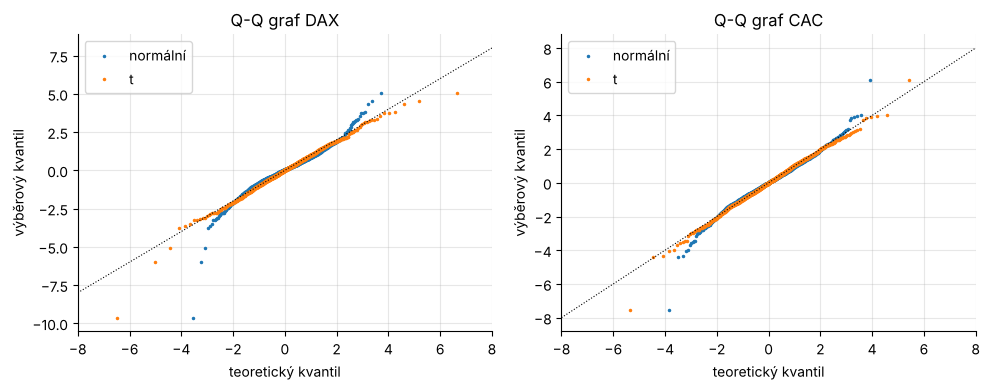

In [19]:
marg = {}
rows = []
for name, z in [('DAX', x), ('CAC', y)]:
    df_, loc, sc = stats.t.fit(z)
    mu, sd = stats.norm.fit(z)
    marg[name] = stats.t(df_, loc, sc)
    rows.append({'index': name, 'nu (t)': df_, 'AIC normální': -2 * stats.norm.logpdf(z, mu, sd).sum() + 4,
                 'AIC t': -2 * stats.t.logpdf(z, df_, loc, sc).sum() + 6,
                 'KS p normální': stats.kstest(z, stats.norm(mu, sd).cdf).pvalue,
                 'KS p t': stats.kstest(z, marg[name].cdf).pvalue})
display(pd.DataFrame(rows).round(4))

fig, axs = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, z) in zip(axs, [('DAX', x), ('CAC', y)]):
    pp = (np.arange(1, n + 1) - 0.5) / n
    ax.plot(stats.norm(*stats.norm.fit(z)).ppf(pp), np.sort(z), '.', ms=3, label='normální')
    ax.plot(marg[name].ppf(pp), np.sort(z), '.', ms=3, label='t')
    ax.plot([-8, 8], [-8, 8], 'k:', lw=0.8); ax.set_xlim(-8, 8)
    ax.set_xlabel('teoretický kvantil'); ax.set_ylabel('výběrový kvantil'); ax.set_title(f'Q-Q graf {name}'); ax.legend()
plt.tight_layout(); plt.show()

$t$-rozdělení (DAX $\nu\approx4{,}7$, CAC $\nu\approx7{,}9$) má podle AIC výrazně lepší shodu než normální; u DAX KS test normalitu zamítá,
Q-Q grafy ukazují, že normální rozdělení nezachytí extrémní dny.
Pro kopuli marginály ale **nepotřebujeme**: odhadujeme ji z pseudo-pozorování (pořadí), tedy bez ohledu na to, jak jsme marginály modelovali.
Marginály využijeme až při simulaci v oddílu 10.4.

## 10.2 Výběr a odhad kopule

Porovnáme Gaussovu, $t$ (oba parametry $\rho,\nu$ odhadujeme), Claytonovu, Gumbelovu, **otočenou (survival) Gumbelovu** a Frankovu kopuli.
Otočená kopule $\bar C(u,v)=u+v-1+C(1-u,1-v)$ vznikne z $(1-U,1-V)$ – Gumbelova kopule tak získá závislost v **dolním** chvostu.
Hustota otočené kopule je $c(1-u,1-v)$.

In [20]:
def fit_all(u, v):
    tau_h = stats.kendalltau(u, v)[0]
    res = {}
    def fit1(name, f, bounds):
        r = optimize.minimize_scalar(lambda p: -np.sum(f(u, v, p)), bounds=bounds, method='bounded')
        res[name] = (r.x, -r.fun, 1)
    fit1('Gaussova', logc_gauss, (-0.99, 0.99))
    r = optimize.minimize(lambda p: -np.sum(logc_t(u, v, p[0], np.exp(p[1]))),
                          [np.sin(np.pi * tau_h / 2), np.log(5)], method='Nelder-Mead')
    res['t'] = ((r.x[0], np.exp(r.x[1])), -r.fun, 2)
    fit1('Clayton', logc_clayton, (1e-3, 30))
    fit1('Gumbel', logc_gumbel, (1.0001, 30))
    fit1('Gumbel otočená', lambda a, b, p: logc_gumbel(1 - a, 1 - b, p), (1.0001, 30))
    fit1('Frank', logc_frank, (-40, 40))
    tab = pd.DataFrame([{'kopule': k, 'parametr': np.round(p, 3), 'log-věrohodnost': ll, 'AIC': -2 * ll + 2 * k_}
                        for k, (p, ll, k_) in res.items()]).sort_values('AIC').reset_index(drop=True)
    return tab, res

tab10, res10 = fit_all(u_hat, v_hat)
display(tab10.round(1))
rho_t, nu_t = res10['t'][0]
th_sg = res10['Gumbel otočená'][0]
rho_g = res10['Gaussova'][0]
print(f't-kopule: rho = {rho_t:.3f}, nu = {nu_t:.2f};  otočená Gumbelova: theta = {th_sg:.3f};  Gaussova: rho = {rho_g:.3f}')

,kopule,parametr,log-věrohodnost,AIC
0,t,"[0.738, 7.723]",696.6,-1389.3
1,Gumbel otočená,2.047,676.7,-1351.5
2,Gaussova,0.737,676.7,-1351.3
3,Gumbel,1.982,619.3,-1236.7
4,Frank,6.213,615.9,-1229.8
5,Clayton,1.583,582.4,-1162.7


t-kopule: rho = 0.738, nu = 7.72;  otočená Gumbelova: theta = 2.047;  Gaussova: rho = 0.737


Nejlepší je **$t$-kopule** ($\nu\approx7{,}7$): symetrická závislost s těžkými chvosty. Otočená Gumbelova (jen dolní chvost)
a Gaussova (bez závislosti v chvostech) vycházejí prakticky stejně, o 38 bodů AIC hůř. Kopule s horním chvostem (Gumbel) nebo bez chvostů (Frank) jsou výrazně horší.
Claytonova kopule (dolní chvost) vychází nejhůř – má sice závislost v dolním chvostu, ale ve středu a v horním chvostu je závislost příliš slabá.

### Totéž s knihovnou `statsmodels`

Modul `statsmodels.distributions.copula.api` obsahuje běžné kopule (log-hustota, distribuční funkce, generování) a třídu `CopulaDistribution`
pro složení kopule s marginály. Metoda `fit_corr_param` odhaduje parametr z Kendallova $\tau$ (inverze vzorců z oddílu 5).

In [21]:
from statsmodels.distributions.copula.api import (GaussianCopula, StudentTCopula, ClaytonCopula,
                                                  GumbelCopula, FrankCopula, CopulaDistribution)
U_hat = np.column_stack([u_hat, v_hat])
for cop in [GaussianCopula(), StudentTCopula(df=nu_t), ClaytonCopula(), GumbelCopula(), FrankCopula()]:
    print(f'{type(cop).__name__:16s} parametr z tau = {cop.fit_corr_param(U_hat):.3f}')
tc = StudentTCopula(corr=rho_t, df=nu_t)
print(f'log-věrohodnost t-kopule (statsmodels) = {tc.logpdf(U_hat).sum():.1f}')

GaussianCopula   parametr z tau = 0.735
StudentTCopula   parametr z tau = 0.735
ClaytonCopula    parametr z tau = 2.215
GumbelCopula     parametr z tau = 2.107
FrankCopula      parametr z tau = 6.219
log-věrohodnost t-kopule (statsmodels) = 696.6


## 10.3 Kontrola – závislost v chvostech

Empirický odhad $\hat\lambda_L(q)=\#\{\hat u_i\le q,\ \hat v_i\le q\}/(nq)$ a $\hat\lambda_U(q)$ obdobně porovnáme s hodnotami
simulovanými z odhadnutých kopulí.

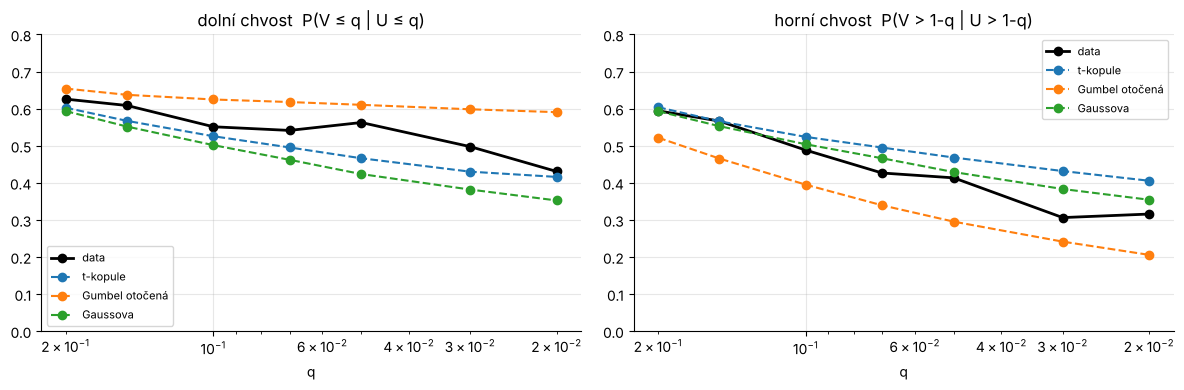

teoretické lambda: t-kopule 0.282 (oba chvosty), otočená Gumbelova lambda_L = 0.597, Gaussova 0


In [22]:
def surv_gumbel(th, n, rng=RNG):
    return 1 - gumbel(th, n, rng)

qs = np.array([0.2, 0.15, 0.1, 0.07, 0.05, 0.03, 0.02])
nbig = 400_000
modely = {'t-kopule': t_cop(rho_t, nu_t, nbig), 'Gumbel otočená': surv_gumbel(th_sg, nbig),
          'Gaussova': gauss_cop(rho_g, nbig)}
lam = lambda U, q: (np.mean((U[:, 0] <= q) & (U[:, 1] <= q)) / q, np.mean((U[:, 0] > 1 - q) & (U[:, 1] > 1 - q)) / q)
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
emp = np.array([lam(U_hat, q) for q in qs])
for j, ax in enumerate(axs):
    ax.plot(qs, emp[:, j], 'ko-', lw=2, label='data')
    for name, U in modely.items():
        ax.plot(qs, [lam(U, q)[j] for q in qs], 'o--', label=name)
    ax.set_xscale('log'); ax.invert_xaxis(); ax.set_xlabel('q'); ax.set_ylim(0, 0.8); ax.legend(fontsize=8)
axs[0].set_title('dolní chvost  P(V ≤ q | U ≤ q)'); axs[1].set_title('horní chvost  P(V > 1-q | U > 1-q)')
plt.tight_layout(); plt.show()
lam_t = 2 * stats.t.cdf(-np.sqrt((nu_t + 1) * (1 - rho_t) / (1 + rho_t)), nu_t + 1)
print(f'teoretické lambda: t-kopule {lam_t:.3f} (oba chvosty), otočená Gumbelova lambda_L = {2 - 2**(1 / th_sg):.3f}, Gaussova 0')

Podmíněná pravděpodobnost současného propadu je v datech kolem 0,5, současného růstu 0,3–0,5 – propady jsou provázanější než růsty
(mírná asymetrie). $t$-kopule je dobrý kompromis: dolní chvost mírně podhodnocuje, horní mírně nadhodnocuje. Otočená Gumbelova kopule
dolní chvost nadhodnocuje a horní výrazně podhodnocuje, Gaussova kopule s klesajícím $q$ podhodnocuje hlavně dolní chvost – tedy právě společné propady.
Empirické hodnoty pro malá $q$ jsou ovšem nejisté – při $q=0{,}02$ jde jen o asi 35 dní.

## 10.4 Použití – riziko portfolia a současné propady

Složíme model: **$t$-marginály** (oddíl 10.1) + **kopule** (oddíl 10.2), $(X,Y)=\big(F_X^{-1}(U),F_Y^{-1}(V)\big)$, a nasimulujeme
milion dní. Pro portfolio 50 % DAX + 50 % CAC spočteme

* **VaR$_{99}$** (Value at Risk) – denní ztráta, která je překročena jen v 1 % dní,
* **ES$_{99}$** (Expected Shortfall) – průměrná ztráta v těchto 1 % nejhorších dní,
* pravděpodobnost, že **oba** indexy současně klesnou pod svůj 1% kvantil (počet takových dní za 10 let, 250 obchodních dní ročně).

Porovnáme s historickými hodnotami a s modely, které závislost v chvostech nemají (Gaussova kopule, dvourozměrné normální rozdělení) nebo ji ignorují úplně (nezávislost).

In [23]:
qx, qy = np.quantile(x, 0.01), np.quantile(y, 0.01)

def riziko(name, X, Y):
    P = 0.5 * X + 0.5 * Y
    var = -np.quantile(P, 0.01)
    return {'model': name, 'VaR99 [%]': var, 'ES99 [%]': -P[P <= -var].mean(),
            'P(oba < 1% kvantil)': np.mean((X < qx) & (Y < qy)),
            'dní za 10 let': np.mean((X < qx) & (Y < qy)) * 2500}

N = 1_000_000
def z_kopule(U):
    return marg['DAX'].ppf(U[:, 0]), marg['CAC'].ppf(U[:, 1])

Z2 = RNG.multivariate_normal([x.mean(), y.mean()], np.cov(x, y), N)
rows = [riziko('historie (data)', x, y),
        riziko('t-marginály + t-kopule', *z_kopule(t_cop(rho_t, nu_t, N))),
        riziko('t-marginály + Gumbel otočená', *z_kopule(surv_gumbel(th_sg, N))),
        riziko('t-marginály + Gaussova kopule', *z_kopule(gauss_cop(rho_g, N))),
        riziko('t-marginály + nezávislost', *z_kopule(RNG.random((N, 2)))),
        riziko('2D normální rozdělení', Z2[:, 0], Z2[:, 1])]
tab_r = pd.DataFrame(rows)
display(tab_r.round(4))
print(f'historicky: {np.sum((x < qx) & (y < qy))} dní ze {n} se současným propadem obou indexů pod 1% kvantil')

,model,VaR99 [%],ES99 [%],P(oba < 1% kvantil),dní za 10 let
0,historie (data),2.5707,3.4728,0.0046,11.4811
1,t-marginály + t-kopule,2.5312,3.2740,0.0035,8.6950
2,t-marginály + Gumbel otočená,2.6287,3.4292,0.0055,13.6650
3,t-marginály + Gaussova kopule,2.5141,3.2168,0.0027,6.6825
4,t-marginály + nezávislost,1.8396,2.2984,0.0001,0.2100
5,2D normální rozdělení,2.3258,2.6736,0.0012,3.0200


historicky: 8 dní ze 1742 se současným propadem obou indexů pod 1% kvantil


**Závěry:**

* Ignorovat závislost (nezávislost) znamená hrubě podcenit riziko: VaR 1,8 % místo 2,6 % a současný propad by nastal jednou za 50 let místo zhruba 11× za 10 let.
* Dvourozměrné normální rozdělení podceňuje riziko kvůli tenkým chvostům marginál i kopule.
* Modely s $t$-marginálami a $t$-kopulí nebo otočenou Gumbelovou kopulí dávají hodnoty blízké historickým; Gaussova kopule
  při stejných marginálách dává podobné VaR, ale počet současných propadů podhodnocuje (chybí závislost v chvostech).
* Výhoda modelu proti samotné historii: můžeme odhadovat i vzácnější události (např. 99,9% kvantil), kterých je v datech jen pár.

**Poznámky k reálné analýze:**

* Finanční výnosy nejsou nezávislé v čase (shlukování volatility). Správnější postup je nejprve odfiltrovat časovou závislost
  (např. model GARCH pro každý index) a kopuli odhadovat z **reziduí** – tzv. *copula-GARCH*.
* Pro více než dvě proměnné se používají eliptické kopule s korelační maticí nebo **vine kopule** (párové kopule skládané do stromů,
  balík `pyvinecopulib`).
* Odhad parametrů kopule je nejistý; interval spolehlivosti lze získat bootstrapem.

---
## Shrnutí

| krok | nástroj |
|---|---|
| oddělit marginály od závislosti | pseudo-pozorování $R_i/(n+1)$, Sklarova věta |
| popsat sílu závislosti | Kendallovo $\tau$, Spearmanovo $\rho_S$ (závisejí jen na kopuli) |
| zvolit rodinu | grafy, závislost v chvostech, $K$-funkce, AIC |
| odhadnout parametr | inverze $\tau$ nebo maximum pseudo-věrohodnosti |
| simulovat | podmíněná metoda, Marshall–Olkin, Gaussova/$t$ přes normální vektor, pak $F^{-1}$ |
| použít | rizika součtu (VaR, ES), pravděpodobnost současných extrémů |
| v knihovně | `statsmodels.distributions.copula.api` |

## Úlohy

1. Vygenerujte data z $t$-kopule ($\nu=3$) a Gaussovy kopule se stejným $\tau$ a porovnejte empirickou závislost chvostů pro $n=500$ a $n=50\,000$.
2. Odvoďte podmíněnou inverzi $h^{-1}$ pro Claytonovu kopuli a ověřte ji simulací (porovnáním s Marshallovým–Olkinovým algoritmem).
3. Na datech `diabetes` odhadněte kopuli pro dvojici `s5` a `target`. Která rodina vyjde nejlépe a proč?
4. Pro marginály $LN(0;1)$ a $LN(0;\sigma^2)$ spočtěte simulací nejmenší a největší dosažitelnou Pearsonovu korelaci (kopule $W$ a $M$) pro $\sigma=1,2,3$.
5. Zopakujte analýzu z oddílu 10 pro dvojici FTSE a SMI. Vyjde opět nejlépe $t$-kopule? Jak se změní VaR portfolia 50/50?